<!-- d2l:prose id=denoising-md-1 fw=all -->

# Denoising and the Score

A network trained by squared error learns the conditional expectation of its target given its input (that section). When we corrupt a clean data point $\mathbf{x}_0 \sim p$ with isotropic Gaussian noise $\sigma \boldsymbol\epsilon$ to form $\tilde{\mathbf{x}} = \mathbf{x}_0 + \sigma \boldsymbol\epsilon$, the optimal least-squares denoiser is therefore the posterior mean $\mathbb{E}[\mathbf{x}_0 \mid \tilde{\mathbf{x}}]$. By *Tweedie's formula* [@Robbins.1956; @Miyasawa.1961; @Efron.2011], this posterior mean is directly determined by the gradient of the log-density of the noised data, $\nabla_{\tilde{\mathbf{x}}} \log p_\sigma(\tilde{\mathbf{x}})$, known as the *score* function. Moreover, @Vincent.2011 showed that regressing a network onto the score of the Gaussian perturbation kernel fits $\nabla_{\tilde{\mathbf{x}}} \log p_\sigma(\tilde{\mathbf{x}})$ without requiring access to the underlying data density $p$.

Learning the score rather than the density itself sidesteps the intractable normalizing constant required by energy-based models, while still providing the vector field needed to generate samples via gradient-based MCMC such as Langevin dynamics. In this section, we first introduce a two-dimensional Gaussian mixture on which the density, score, and posterior mean are exact at every noise level. We use this benchmark to verify Tweedie's formula, examine why a score model trained at any single noise level $\sigma$ cannot simultaneously resolve local mode structure and global mode weights, and finally apply single-level denoising to Fashion-MNIST images.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
torch.set_float32_matmul_precision('high')  # tf32 matmuls on tensor cores

<!-- d2l:prose id=denoising-md-2 fw=all -->

## The Running Example

We want one distribution on which every quantity of the chapter is exact at every noise level, so that each learned field and sampler can be checked against the truth. A mixture of Gaussians in the plane will do. Ours has three components with means $(-2.5, -1.5)$, $(2.5, -1.5)$ and $(0, 2.5)$, mixture weights $\pi_k = 0.5, 0.3, 0.2$, and a common standard deviation $s = 0.5$ per coordinate. The modes are far apart compared with their width, so the density has deep valleys between them, and the unequal weights give a sampler something to get wrong.

The *score* of a density $p$ is the gradient of its logarithm, $\nabla \log p(\mathbf{x})$, a vector field that points in the direction in which the density grows fastest. For the mixture $p(\mathbf{x}) = \sum_k \pi_k\, \mathcal{N}(\mathbf{x}; \boldsymbol\mu_k, s^2\mathbf{I})$ it reads

$$
\begin{aligned}
\nabla \log p(\mathbf{x}) &= \sum_k r_k(\mathbf{x})\, \frac{\boldsymbol\mu_k - \mathbf{x}}{s^2}, \\
r_k(\mathbf{x}) &= \frac{\pi_k\, \mathcal{N}(\mathbf{x}; \boldsymbol\mu_k, s^2\mathbf{I})}{p(\mathbf{x})}.
\end{aligned}
$$

Each component pulls the point toward its own mean, and the pulls are averaged with the *responsibilities* $r_k(\mathbf{x})$, the posterior probabilities that $\mathbf{x}$ was drawn from component $k$ (the figure). The weights $\pi_k$ enter only through the responsibilities. Near a mode one responsibility is close to one whatever the weights are, so the weights change the score only in the valleys, where few points lie. The remark looks harmless, but it will decide what a score model can learn.

![The score is the gradient of the log-density. Left: a bimodal density in one dimension (top) and its score (bottom), zero at both modes and at the valley between them. Right: the running example, with its density as shaded contours and its score field as arrows that point toward the modes (arrow lengths clipped).](../img/mdl-diffusion-score-field.svg)

Noise keeps a mixture of Gaussians a mixture of Gaussians. Adding Gaussian noise of standard deviation $\sigma$ to a draw adds $\sigma^2$ to the variance of each component, so $s^2$ becomes $s^2 + \sigma^2$, and the density, score and posterior mean have closed forms at every noise level. The class below evaluates all three; its argument `alpha`, a scale on the clean point, stays at one until the next section.

In [3]:
class GaussianMixture:
    """A mixture of isotropic Gaussians, exact at every noise level."""
    def __init__(self, means, weights, std, device=None):
        self.means = torch.tensor(means, dtype=torch.float32, device=device)
        self.weights = torch.tensor(weights, dtype=torch.float32,
                                    device=device)
        self.std = std

    @staticmethod
    def three_modes(device=None):
        """The chapter's running example, with mode weights 0.5/0.3/0.2."""
        return GaussianMixture([[-2.5, -1.5], [2.5, -1.5], [0.0, 2.5]],
                               [0.5, 0.3, 0.2], 0.5, device)

    def sample(self, n):
        """n draws from the mixture."""
        k = torch.multinomial(self.weights, n, replacement=True)
        return self.means[k] + self.std * torch.randn(
            n, self.means.shape[1], device=self.means.device)

    def _modes(self, x, alpha, sigma):
        """Per-mode log densities, offsets x - alpha mu_k, variances, alpha."""
        a, s = (torch.as_tensor(v, dtype=x.dtype, device=x.device)
                .reshape(-1, 1, 1) for v in (alpha, sigma))
        var = (a * self.std) ** 2 + s ** 2
        r = x[:, None] - a * self.means
        log_p = (torch.log(self.weights) - (r ** 2).sum(-1) / (2 * var[..., 0])
                 - x.shape[1] / 2 * torch.log(2 * torch.pi * var[..., 0]))
        return log_p, r, var, a

    def log_prob(self, x, alpha=1.0, sigma=0.0):
        """log p(x) for x = alpha x0 + sigma eps."""
        return torch.logsumexp(self._modes(x, alpha, sigma)[0], 1)

    def score(self, x, alpha=1.0, sigma=0.0):
        """The gradient of log p(x) for x = alpha x0 + sigma eps."""
        log_p, r, var, _ = self._modes(x, alpha, sigma)
        return -(torch.softmax(log_p, 1)[..., None] * r / var).sum(1)

    def posterior_mean(self, x, alpha, sigma):
        """E[x0 | x]; finite at alpha = 0 and at sigma = 0."""
        log_p, r, var, a = self._modes(x, alpha, sigma)
        return (torch.softmax(log_p, 1)[..., None]
                * (self.means + a * self.std ** 2 / var * r)).sum(1)

<!-- d2l:prose id=denoising-md-3 fw=all -->

Throughout the chapter, samplers on this mixture are judged by the same yardsticks: the mean negative log-likelihood of their points under the true density, and three numbers from `summary`. The *mode weights* count each point at its nearest mean. The *strays* are the fraction of points farther than $3s = 1.5$ from every mean. The *spread* is the mean squared distance of the remaining points to their nearest mean; since it ignores the strays, it can never exceed $(3s)^2 = 2.25$, and a sampler that is far too wide shows up mainly as strays.

In [4]:
@d2l.add_to_class(GaussianMixture)
def nll(self, x):
    """Mean negative log-likelihood of clean points, in nats."""
    return -self.log_prob(x).mean()

@d2l.add_to_class(GaussianMixture)
def summary(self, x):
    """Mode weights by nearest mean, stray fraction, spread of the rest."""
    d2 = ((x[:, None] - self.means) ** 2).sum(-1)
    near, k = d2.min(1)
    inside = near < (3 * self.std) ** 2
    weights = torch.bincount(k, minlength=len(self.weights)) / len(x)
    return dict(weights=[round(w, 3) for w in weights.tolist()],
                stray=round(1 - inside.float().mean().item(), 4),
                spread=round(near[inside].mean().item(), 3))

<!-- d2l:prose id=denoising-md-4 fw=all -->

To compare 2D point clouds visually alongside these numerical summaries,
`scatter_panels` plots one or more sample sets side by side on shared axes
(optionally overlaying a reference dataset `data` in light gray):

In [5]:
def scatter_panels(samples, titles=None, data=None, lim=4.5,
                   size=3.0):
    """Scatter 2-D point sets side by side on equal, shared axes."""
    _, axes = d2l.plt.subplots(1, len(samples), squeeze=False,
                               figsize=(size * len(samples), size))
    for i, (ax, pts) in enumerate(zip(axes[0], samples)):
        if data is not None:
            ax.scatter(*d2l.numpy(data).T, s=2, c='lightgray')
        ax.scatter(*d2l.numpy(pts).T, s=2)
        ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect='equal')
        if titles:
            ax.set_title(titles[i])
    return axes[0]

<!-- d2l:prose id=denoising-md-5 fw=all -->

What should a perfect sampler print? The weights $0.5$, $0.3$ and $0.2$, up to sampling noise. In two dimensions the squared distance of a Gaussian draw from its mean is exponentially distributed with mean $2s^2 = 0.5$, so a fraction $e^{-(3s)^2/(2s^2)} = e^{-4.5} \approx 1\%$ of the points stray, and the spread of the rest is a little below $0.5$. We check this on 2,000 draws, the training set of the section's two-dimensional experiments.

{'weights': [0.5, 0.317, 0.183], 'stray': 0.012, 'spread': 0.488} NLL 2.504


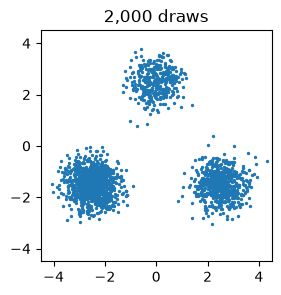

In [6]:
torch.manual_seed(0)
mix = d2l.GaussianMixture.three_modes()
data = mix.sample(2000)
print(mix.summary(data), f'NLL {mix.nll(data):.3f}')
d2l.scatter_panels([data], ['2,000 draws']);

<!-- d2l:prose id=denoising-md-6 fw=all -->

The draws print what we predicted. These are the values every sampler on the mixture aims for. The negative log-likelihood needs a word of care. About $2.5$ nats per point is the entropy of the mixture: no density model scores fresh data lower on average, and the points of a correct sampler score about this much under $p$. For a sampler it is a target, not a bound to beat: points crowded at the modes score less, and points in the valleys more.

## The Optimal Denoiser

The regression of the opening has two natural targets, the clean point and a vector that points to it. The identity that links their minimizers is the most important result of this section.

### Noise and the Regression Target

Pick a noise level $\sigma > 0$, draw a clean point $\mathbf{x}_0 \sim p$ and standard Gaussian noise $\boldsymbol\epsilon \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$, and form the noisy point $\tilde{\mathbf{x}} = \mathbf{x}_0 + \sigma \boldsymbol\epsilon$. Its density $p_\sigma$ is the data density blurred by a Gaussian of width $\sigma$, positive and smooth everywhere even when $p$ is not. A denoiser $D$ is trained to minimize $\mathbb{E}\|D(\tilde{\mathbf{x}}) - \mathbf{x}_0\|^2$. Squared error is minimized by the conditional mean of the target given the input, the fact recalled at the start of this section (that section), so the optimal denoiser is the *posterior mean* $\mathbb{E}[\mathbf{x}_0 \mid \tilde{\mathbf{x}}]$: the average of the clean points that could have produced $\tilde{\mathbf{x}}$, each weighted by how likely it is to have done so.

The same regression can aim at a different target. Given the clean point, the noisy point is Gaussian around it, and the score of this conditional density is

$$
\nabla_{\tilde{\mathbf{x}}} \log p_\sigma(\tilde{\mathbf{x}} \mid \mathbf{x}_0)
= \frac{\mathbf{x}_0 - \tilde{\mathbf{x}}}{\sigma^2}
= -\frac{\boldsymbol\epsilon}{\sigma},
$$

a vector pointing from the noisy point back to the clean one. *Denoising score matching* regresses a vector field $\mathbf{s}_{\boldsymbol\theta}$ onto it [@Vincent.2011]:

$$
\begin{aligned}
J_{\mathrm{DSM}}(\boldsymbol\theta)
&= \tfrac12\, \mathbb{E}_{\mathbf{x}_0, \boldsymbol\epsilon}
\Big\| \mathbf{s}_{\boldsymbol\theta}(\mathbf{x}_0 + \sigma \boldsymbol\epsilon) + \frac{\boldsymbol\epsilon}{\sigma} \Big\|^2.
\end{aligned}
$$

The minimizer is again a conditional mean, now of the conditional score, and Vincent's theorem identifies it: *the score of the noised data is the posterior mean of the conditional score*,

$$
\mathbb{E}\Big[ -\frac{\boldsymbol\epsilon}{\sigma} \,\Big|\, \tilde{\mathbf{x}} \Big] = \nabla \log p_\sigma(\tilde{\mathbf{x}}).
$$

The proof is two lines of Bayes' rule. The noisy density is the clean one blurred by the noise, $p_\sigma(\tilde{\mathbf{x}}) = \int p(\mathbf{x}_0)\, p_\sigma(\tilde{\mathbf{x}} \mid \mathbf{x}_0)\, d\mathbf{x}_0$. Differentiate under the integral, write the gradient of the kernel as the kernel times the gradient of its logarithm, and divide by $p_\sigma(\tilde{\mathbf{x}})$:

$$
\begin{aligned}
\nabla \log p_\sigma(\tilde{\mathbf{x}})
&= \int \frac{p(\mathbf{x}_0)\, p_\sigma(\tilde{\mathbf{x}} \mid \mathbf{x}_0)}{p_\sigma(\tilde{\mathbf{x}})}\, \nabla_{\tilde{\mathbf{x}}} \log p_\sigma(\tilde{\mathbf{x}} \mid \mathbf{x}_0)\, d\mathbf{x}_0.
\end{aligned}
$$

The fraction is Bayes' rule for the posterior $p(\mathbf{x}_0 \mid \tilde{\mathbf{x}})$, so the right-hand side is the posterior mean of the conditional score, which is the equation. Nothing in the two lines used that the noise is Gaussian; the conditions under which the gradient may move inside the integral are in that section.

The regression on per-pair targets therefore fits the score of $p_\sigma$, which we never wrote down. This is the reason the chapter can train generators by regression at all: we cannot evaluate the score of the data, but we can evaluate the score of the noise we added ourselves.

### Tweedie's Formula

The two regressions, onto the clean point and onto $-\boldsymbol\epsilon/\sigma$, have targets related by the map $\mathbf{x}_0 \mapsto (\mathbf{x}_0 - \tilde{\mathbf{x}})/\sigma^2$, which is affine once $\tilde{\mathbf{x}}$ is given, so their minimizers, two conditional means, are related by the same map. Solving for the posterior mean gives *Tweedie's formula* [@Efron.2011],

$$
\mathbb{E}[\mathbf{x}_0 \mid \tilde{\mathbf{x}}] = \tilde{\mathbf{x}} + \sigma^2\, \nabla \log p_\sigma(\tilde{\mathbf{x}}).
$$

The best denoiser takes one step of size $\sigma^2$ up the score of the noisy density (the figure). A denoiser, a score and a noise predictor are therefore three ways of writing one posterior mean:

$$
\begin{aligned}
\hat{\mathbf{x}}_0(\tilde{\mathbf{x}}) &= \tilde{\mathbf{x}} + \sigma^2\, \hat{\mathbf{s}}(\tilde{\mathbf{x}}), \\
\hat{\boldsymbol\epsilon}(\tilde{\mathbf{x}}) &= \frac{\tilde{\mathbf{x}} - \hat{\mathbf{x}}_0(\tilde{\mathbf{x}})}{\sigma} = -\sigma\, \hat{\mathbf{s}}(\tilde{\mathbf{x}}).
\end{aligned}
$$

A network trained to output any one of the three gives the other two.

The smallest case shows what the step does. Let the data be Gaussian, $\mathcal{N}(\boldsymbol\mu, v\mathbf{I})$. Then $p_\sigma = \mathcal{N}(\boldsymbol\mu, (v + \sigma^2)\mathbf{I})$ has the score $-(\tilde{\mathbf{x}} - \boldsymbol\mu)/(v + \sigma^2)$, and Tweedie's formula gives

$$
\mathbb{E}[\mathbf{x}_0 \mid \tilde{\mathbf{x}}] = \boldsymbol\mu + \frac{v}{v + \sigma^2}\, (\tilde{\mathbf{x}} - \boldsymbol\mu).
$$

The denoiser shrinks the noisy offset from the mean by the factor $v/(v + \sigma^2)$, and the posterior variance per coordinate is $v\sigma^2/(v + \sigma^2)$. With $v = s^2 = 0.25$ and $\sigma = 0.3$ the factor is $0.74$, and the squared error per coordinate falls from $\sigma^2 = 0.09$ to $0.066$. Away from the valleys the posterior mean of the running example is this shrinkage toward the nearest mean, so over the two coordinates of a point denoising should lower the squared error from $0.18$ to about $0.13$.

### A Trained Score

Does a learned score reach this best denoiser? To find out we need a network, and the chapter uses one small MLP for all its two-dimensional experiments. Besides the point it reads sines and cosines of the noise level (from the next section on, of a time $t \in [0, 1]$ along a path from data to noise). Here the level is fixed and these features do nothing. From the next section on, one network serves every level and must tell nearby levels apart, so the frequencies run from 1 to 64 radians per unit of $t$, and the fastest features complete about ten periods on $[0, 1]$. The positional encodings of that section, built for integer token positions in the thousands, would be nearly constant or linear on this interval. The few-step generators of that section lower the frequencies again, for a reason given there.

In [7]:
def time_embedding(t, dim, freqs=(1.0, 64.0)):
    """Sines and cosines of t at dim / 2 frequencies, geometric from freqs[0]
    to freqs[1] radians per unit of t (t in [0, 1])."""
    f = torch.exp(torch.linspace(math.log(freqs[0]), math.log(freqs[1]),
                                 dim // 2, device=t.device))
    args = t.float()[:, None] * f
    return torch.cat([args.sin(), args.cos()], 1)

class TimeMLP(nn.Module):
    """An MLP on a point x and the time features of one or more times;
    time_freqs: see time_embedding."""
    def __init__(self, hidden=256, depth=3, *, dim=2, num_times=1,
                 time_dim=64, time_freqs=(1.0, 64.0)):
        super().__init__()
        self.time_dim, self.time_freqs = time_dim, time_freqs
        self.embed = d2l.make_mlp([time_dim * num_times, hidden, hidden],
                                  nn.SiLU())
        self.inp = nn.Linear(dim, hidden)
        self.body = nn.Sequential(  # depth layers, each after a SiLU
            nn.SiLU(), d2l.make_mlp([hidden] * depth + [dim], nn.SiLU()))

    def forward(self, x, *ts):
        feats = [time_embedding(t, self.time_dim, self.time_freqs) for t in ts]
        return self.body(self.inp(x) + self.embed(torch.cat(feats, 1)))

<!-- d2l:prose id=denoising-md-7 fw=all -->

One training loop serves the whole chapter: Adam on a fresh minibatch with fresh noise at every step. It also keeps an exponential moving average (EMA) of the weights, which matters from that section on; its docstring lists the other options.

In [8]:
def train_regression(model, loss_fn, batch_fn, num_steps, *,
                     lr=1e-3, cosine=False, ema_half_life=1000,
                     compiled=True):
    """Adam on loss_fn(model, batch_fn()) -> (model, EMA model, losses).

    The learning rate is constant or, with cosine=True, decays to zero along
    a cosine. The EMA model averages the weights (d2l.EMA): the weights of
    ema_half_life updates ago count half as much as the current ones. On a
    GPU, Adam is fused into one kernel and, with compiled=True, the loss and
    its gradient run as CUDA graphs: the networks of this chapter are so
    small that launching their kernels one at a time would cost more time
    than running them."""
    params = list(model.parameters())
    opt = torch.optim.Adam(params, lr=lr, fused=params[0].is_cuda)
    sched = (torch.optim.lr_scheduler.CosineAnnealingLR(opt, num_steps)
             if cosine else None)
    if compiled and params[0].is_cuda:  # loss and gradient as CUDA graphs
        loss_fn = torch.compile(loss_fn, mode='reduce-overhead',
                                dynamic=False)
    ema, losses = d2l.EMA(model, ema_half_life), []
    for _ in range(num_steps):
        loss = loss_fn(model, batch_fn())
        opt.zero_grad()
        loss.backward()
        opt.step()
        if sched:
            sched.step()
        ema.update(model)
        losses.append(loss.detach().clone())  # the graph reuses its output
    return model, ema.model, torch.stack(losses)

<!-- d2l:prose id=denoising-md-8 fw=all -->

For the mixture, a network with two hidden layers of 128 units minimizes the equation for 2,000 steps, each on 256 of the 2,000 training points with fresh noise, and we keep the trained score as a function of the point alone.

In [9]:
def dsm_loss(net, x, sigma):
    """Denoising score matching at one noise level: regress onto -eps/sigma."""
    eps = torch.randn_like(x)
    s = net(x + sigma * eps, torch.full((len(x),), sigma))
    return 0.5 * ((s + eps / sigma) ** 2).sum(1).mean()

def fit_score(data, sigma, seed=1, num_steps=2000):
    """Train a score network at one noise level and return it as a function."""
    torch.manual_seed(seed)
    batch_fn = lambda: data[torch.randint(0, len(data), (256,))]
    net, _, _ = d2l.train_regression(
        d2l.TimeMLP(128, 2), lambda net, x: dsm_loss(net, x, sigma),
        batch_fn, num_steps)
    return lambda x: net(x, torch.full((len(x),), sigma)).detach()

<!-- d2l:prose id=denoising-md-9 fw=all -->

At $\sigma = 0.3$ we noise 20,000 fresh points and compare three guesses of the clean point: the noisy point itself, the exact posterior mean, and Tweedie's step with the trained score.

In [10]:
sigma = 0.3
score = fit_score(data, sigma)
x0 = mix.sample(20000)
xt = x0 + sigma * torch.randn_like(x0)
exact = mix.posterior_mean(xt, 1.0, sigma)
for name, x0_hat in (('noisy point', xt), ('posterior mean', exact),
                     ('Tweedie, trained score', xt + sigma ** 2 * score(xt))):
    print(f'{name}: squared error {((x0_hat - x0) ** 2).sum(1).mean():.4f}')

noisy point: squared error 0.1782
posterior mean: squared error 0.1317
Tweedie, trained score: squared error 0.1328


<!-- d2l:prose id=denoising-md-10 fw=all -->

The exact posterior mean lowers the squared error from $0.18$ to about $0.13$, as the Gaussian case predicted, and Tweedie's step with the trained score comes within about one percent of it. After 2,000 steps on 2,000 points the network is a nearly optimal denoiser, and therefore a usable score.

As a score it is a little less good than that sounds. The score enters the denoiser multiplied by $\sigma^2 = 0.09$, and in expectation the excess error of Tweedie's step over the posterior mean is exactly $\sigma^4$ times the mean squared error of the score; the cross term vanishes because the error of the posterior mean averages to zero given $\tilde{\mathbf{x}}$. The gap of about $0.001$ thus stands for a score error $\tfrac12\mathbb{E}\|\hat{\mathbf{s}} - \nabla \log p_\sigma\|^2$ of about $0.06$. A denoiser can look nearly perfect while its score is visibly off, and the score is what a sampler follows.

### Scores and Normalizers

Why learn a score rather than a density? A network with a scalar output $E_{\boldsymbol\theta}$, called the *energy*, defines a density through an *energy-based model*,

$$
p_{\boldsymbol\theta}(\mathbf{x}) = \frac{\exp(-E_{\boldsymbol\theta}(\mathbf{x}))}{Z_{\boldsymbol\theta}},
\qquad
Z_{\boldsymbol\theta} = \int \exp(-E_{\boldsymbol\theta}(\mathbf{x}))\, d\mathbf{x}.
$$

The normalizer is what makes learning meaningful: since the total mass is fixed, raising the density on the training points lowers it elsewhere. Unfortunately $Z_{\boldsymbol\theta}$ is an integral over the whole input space that changes with every update, and the gradient of the log-likelihood contains $\nabla_{\boldsymbol\theta} \log Z_{\boldsymbol\theta} = -\mathbb{E}_{p_{\boldsymbol\theta}}[\nabla_{\boldsymbol\theta} E_{\boldsymbol\theta}]$, an expectation that has to be estimated by sampling from the model, in practice with a Markov chain. The score does not see $Z_{\boldsymbol\theta}$ at all, because $Z_{\boldsymbol\theta}$ does not depend on $\mathbf{x}$: $\nabla_{\mathbf{x}} \log p_{\boldsymbol\theta} = -\nabla_{\mathbf{x}} E_{\boldsymbol\theta}$.

A field $\mathbf{s}$ is compared with the data by the *Fisher divergence*, the mean squared distance between the two fields where the data lie:

$$
D_{\mathrm{F}}(p, \mathbf{s}) = \tfrac12\, \mathbb{E}_{\mathbf{x} \sim p} \big\| \mathbf{s}(\mathbf{x}) - \nabla \log p(\mathbf{x}) \big\|^2.
$$

It contains the unknown data score, which *Hyvärinen's identity* [@Hyvarinen.2005] removes by integration by parts: up to a constant, $D_{\mathrm{F}}$ equals $\mathbb{E}_{p}[\tfrac12\|\mathbf{s}\|^2 + \nabla \cdot \mathbf{s}]$, an average over data with no normalizer and no chain (that section). Its second term, $\nabla \cdot \mathbf{s}$, the trace of the Jacobian of $\mathbf{s}$, costs one backward pass per input dimension, too many for images. Denoising removes that cost as well: by Vincent's theorem, the equation is the Fisher divergence to $p_\sigma$ up to a constant.

## Limits of a Single Noise Level

A denoiser trained at one noise level gives the score of one blurred distribution, $p_\sigma$. To sample $p$ we want the score of $p$, so the first question is which $\sigma$ to choose.

### Choosing the Noise Level

A small noise level has two problems. The first is statistical. For data with a smooth density, such as the running example, the target $-\boldsymbol\epsilon/\sigma$ grows like $1/\sigma$ while the score it averages to stays bounded, so at small $\sigma$ the target is mostly noise and the network fits it poorly. Even the exact score leaves the variance of the target around its conditional mean in the loss, and in $d$ dimensions this floor grows like $d/\sigma^2$ as $\sigma$ shrinks (that section). A denoising loss that levels off well above zero is therefore no sign of a bad network.

The second problem matters most for images, which are believed to lie near a low-dimensional set inside pixel space [@Bengio.Courville.Vincent.2013]. Let us take the extreme case of data on a line in the plane. Noise thickens the line into a band across which $p_\sigma$ is a Gaussian of variance $\sigma^2$, so the score across the band is $-\tilde{x}_2/\sigma^2$ at distance $\tilde{x}_2$ from the line (Exercise 3). Its slope, $-1/\sigma^2$, grows without bound as $\sigma \to 0$. Across the band the target $-\epsilon_2/\sigma$ equals this score exactly, so the trouble is not noise there: the network must represent a field that turns into a cliff across the data set, while along it the targets are mostly noise.

A large noise level has the opposite problem. The regression is well conditioned, but its answer is the score of $p_\sigma$, not of $p$. For one Gaussian component $\mathcal{N}(\boldsymbol\mu, s^2\mathbf{I})$ in $d$ dimensions the two scores are $-(\mathbf{x} - \boldsymbol\mu)/(s^2 + \sigma^2)$ and $-(\mathbf{x} - \boldsymbol\mu)/s^2$, and averaging the squared norm of their difference over $p$ gives the bias

$$
\begin{aligned}
\tfrac12\, \mathbb{E}_p \big\| \nabla \log p_\sigma - \nabla \log p \big\|^2
&= \frac{d\, \sigma^4}{2 s^2 (s^2 + \sigma^2)^2}.
\end{aligned}
$$

The bias grows like $\sigma^4$ at first. For $s = 0.5$ and $d = 2$ it is $0.0004$ at $\sigma = 0.05$, $0.28$ at $\sigma = 0.3$ and $2.6$ at $\sigma = 1$, and the well-separated mixture has nearly the same values. Divided by the size of the clean score, $\tfrac12 \mathbb{E}_p\|\nabla \log p\|^2 = d/(2s^2)$, it becomes $(\sigma^2/(s^2 + \sigma^2))^2$, which depends only on $\sigma/s$. The smoothed score stays within $10\%$ of the clean one, in root-mean-square terms, while $\sigma < s/3 \approx 0.17$, so we should expect the bias to start to matter near there.

Between the two problems there should be a best level. We train a network at each of seven levels from $0.05$ to $1$, with two seeds, and estimate the Fisher divergence the equation of each from the clean score on 20,000 test points, next to the bias of the exact smoothed score.

trained, seed 1: [0.423, 0.189, 0.215, 0.3, 0.409, 1.077, 2.559]
trained, seed 2: [0.541, 0.285, 0.255, 0.252, 0.363, 1.019, 2.532]
exact smoothed:  [0.0004, 0.0059, 0.0271, 0.0755, 0.2781, 0.9924, 2.5538]


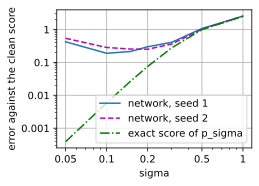

In [11]:
sigmas, seeds = [0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 1.0], (1, 2)
scores = {(sg, seed): fit_score(data, sg, seed)
          for seed in seeds for sg in sigmas}
x_test = mix.sample(20000)
target = mix.score(x_test)                     # the clean score
def score_error(score, x, target):
    return 0.5 * ((score(x) - target) ** 2).sum(1).mean().item()
learned = {seed: [score_error(scores[sg, seed], x_test, target)
                  for sg in sigmas] for seed in seeds}
bias = [score_error(lambda x: mix.score(x, 1.0, sg), x_test, target)
        for sg in sigmas]
for seed in seeds:
    print(f'trained, seed {seed}:', [round(e, 3) for e in learned[seed]])
print('exact smoothed: ', [round(e, 4) for e in bias])
d2l.plot(sigmas, [*learned.values(), bias], 'sigma',
         'error against the clean score', xscale='log', yscale='log',
         legend=[f'network, seed {seed}' for seed in seeds]
         + ['exact score of p_sigma'])

<!-- d2l:prose id=denoising-md-11 fw=all -->

The learned error traces a U. To the right it follows the bias line, within about $0.1$ from $\sigma = 0.5$ on: the networks fit their blurred targets well, and the targets are wrong. To the left it rises again although the bias vanishes, because the targets are mostly noise, and the second seed changes some errors there by half or more. The best level lies between $\sigma = 0.1$ and $0.2$, a fifth to two fifths of the component width and around the $s/3$ of the bias rule, at an error of about $0.15$ to $0.25$. That is the rule for a single level: measure $\sigma$ in units of the scale of the data, and take it as small as the network can still fit.

### Blindness to Mode Weights

An error of $0.2$ in the Fisher divergence sounds small, but small compared with what? Compare the running example with its equal-weight copy. A model with these wrong weights loses $0.07$ nats of likelihood per point, their Kullback--Leibler divergence. Its score, however, differs from the true one only through the responsibilities in the equation, which differ only in the valleys, where $p$ is nearly zero, so the Fisher divergence, an average under $p$, barely sees the difference.

We compute both divergences by quadrature on a $721 \times 721$ grid rather than by sampling, because the Fisher integrand lives in the valleys, where few Monte Carlo draws land, and then repeat the comparison with both mixtures blurred by the same noise.

In [12]:
mix_eq = d2l.GaussianMixture(mix.means.tolist(), [1 / 3] * 3, mix.std)
g = torch.linspace(-9, 9, 721)
grid = torch.stack(torch.meshgrid(g, g, indexing='ij'), -1).reshape(-1, 2)
area = (g[1] - g[0]) ** 2                      # of one grid cell
for sigma in (0.0, 0.5, 1.0):
    log_p = mix.log_prob(grid, 1.0, sigma)
    diff = mix.score(grid, 1.0, sigma) - mix_eq.score(grid, 1.0, sigma)
    fisher = area * (log_p.exp() * 0.5 * (diff ** 2).sum(1)).sum()
    kl = area * (log_p.exp()
                 * (log_p - mix_eq.log_prob(grid, 1.0, sigma))).sum()
    print(f'sigma = {sigma}: Fisher divergence {fisher:.1e}, KL {kl:.3f} nats')

sigma = 0.0: Fisher divergence 1.5e-05, KL 0.069 nats
sigma = 0.5: Fisher divergence 1.4e-03, KL 0.069 nats


sigma = 1.0: Fisher divergence 9.5e-03, KL 0.064 nats


<!-- d2l:prose id=denoising-md-12 fw=all -->

Between the clean mixtures the Fisher divergence is about $10^{-5}$, four orders of magnitude below the errors of the trained networks, none of which fell below $0.1$, while the KL divergence is $0.07$ nats. A score model trained near the clean data therefore cannot learn the weights: a field with the wrong weights fits as well as one with the right weights (that section; Exercise 2 of that section). A score can be excellent near the data and still know nothing about how often each mode occurs.

Noise makes the weights visible. As $\sigma$ grows, the components spread into the valleys (the figure), the responsibilities differ where $p_\sigma$ has mass, and the Fisher divergence rises to about $10^{-3}$ at $\sigma = 0.5$ and $10^{-2}$ at $\sigma = 1$, while the KL divergence barely changes. Even at $\sigma = 1$ this Fisher divergence is more than ten times smaller than any error in the sweep, so noise alone does not make the weights easy to learn. What it changes first is that chains can cross the valleys.

![The running example blurred by Gaussian noise of growing standard deviation $\sigma$; crosses mark the component means. As $\sigma$ grows, the valleys between the modes fill in, until at $\sigma = 2$ a single broad bump remains.](../img/mdl-diffusion-noise-ladder.svg)

### Sampling with a Score

A score is enough to draw samples, and the simplest way to do it is more than a century old. Paul Langevin wrote down an equation of this kind in 1908 for a particle in a fluid, pushed by a force and kicked at random by the molecules around it. In discrete form, *Langevin dynamics* starts from any point and repeats

$$
\mathbf{x} \leftarrow \mathbf{x} + \frac{h}{2}\, \mathbf{s}(\mathbf{x}) + \sqrt{h}\, \boldsymbol\xi,
\qquad \boldsymbol\xi \sim \mathcal{N}(\mathbf{0}, \mathbf{I}),
$$

with a small step size $h$. The drift moves the point up the log-density, and the noise keeps it from collapsing onto a mode. In the continuous-time limit, $p$ is the stationary distribution whenever $\mathbf{s} = \nabla \log p$ (that section), and a chain run long enough forgets its start. The discrete update is slightly off: for a Gaussian of variance $v$ its stationary variance is $v/(1 - h/(4v))$, a five percent excess for our components at $h = 0.05$. Nothing in the update refers to a density, so any vector field can drive it, including a trained one that is not the gradient of anything.

In [13]:
@torch.no_grad()
def langevin(score_fn, x, step, num_steps):
    """Langevin steps x <- x + step / 2 * score + sqrt(step) * noise."""
    for _ in range(num_steps):
        x = x + step / 2 * score_fn(x) + step ** 0.5 * torch.randn_like(x)
    return x

<!-- d2l:prose id=denoising-md-13 fw=all -->

We start 2,000 chains from $\mathcal{N}(\mathbf{0}, 9\mathbf{I})$, so that each mode receives about a third of them, and run 2,000 steps at $h = 0.05$ with five fields: the exact score of $p$; the exact scores of $p_\sigma$ at $\sigma = 1$ and at $\sigma = 0.3$, printed as `p_1` and `p_0.3`; and the two networks of the sweep trained at $\sigma = 0.3$, used as if they were the score of $p$. The exact field at $0.3$ is the one the networks were trained to imitate, so it tells us which of their behavior is the noise level's and which is their own.

With the exact score of $p$, should the chains end with the weights $0.5$, $0.3$ and $0.2$? They should, if 2,000 steps are long enough for a chain to forget its start. The chains at $\sigma = 1$ should sample $p_\sigma$, whose components have variance $s^2 + \sigma^2 = 1.25$ per coordinate, five times that of $p$. The calculation for the perfect sampler, with $2 \cdot 1.25$ in place of $2s^2$, predicts $e^{-2.25/2.5} \approx 41\%$ strays and a spread near $1$, only about twice the data's.

In [14]:
torch.manual_seed(2)
x_init = 3 * torch.randn(2000, 2)
fields = {'p': mix.score,                     # exact scores of p, p_1, p_0.3
          'p_1': lambda x: mix.score(x, 1, 1),
          'p_0.3': lambda x: mix.score(x, 1, 0.3),
          'net 0.3, seed 1': scores[0.3, 1],   # trained at sigma = 0.3
          'net 0.3, seed 2': scores[0.3, 2]}
samples = [d2l.langevin(f, x_init, 0.05, 2000) for f in fields.values()]
print(f'{"start":>15}:', mix.summary(x_init))
print(f'{"data":>15}:', mix.summary(data))
for name, x in zip(fields, samples):
    print(f'{name:>15}:', mix.summary(x))
d2l.scatter_panels(samples, list(fields), data=data, size=2.3);

          start: {'weights': [0.308, 0.329, 0.363], 'stray': 0.751, 'spread': 1.051}
           data: {'weights': [0.5, 0.317, 0.183], 'stray': 0.012, 'spread': 0.488}
              p: {'weights': [0.312, 0.335, 0.354], 'stray': 0.0095, 'spread': 0.501}
            p_1: {'weights': [0.498, 0.298, 0.204], 'stray': 0.4245, 'spread': 0.986}
          p_0.3: {'weights': [0.329, 0.334, 0.338], 'stray': 0.0435, 'spread': 0.627}
net 0.3, seed 1: {'weights': [0.454, 0.262, 0.284], 'stray': 0.0485, 'spread': 0.625}
net 0.3, seed 2: {'weights': [0.458, 0.289, 0.253], 'stray': 0.0525, 'spread': 0.628}


<!-- d2l:prose id=denoising-md-14 fw=all -->

The exact score of $p$ drives every chain into a mode with the right local spread, but the mode weights remain at their initial values ($\approx 1/3$ each). Because the valleys between modes lie 10 to 12 nats above the modes in $-\log p$, the expected Kramers escape time is on the order of $10^6$ steps at $h = 0.05$ (Exercise 6); 2,000 steps cannot mix across modes. Conversely, at $\sigma = 1$ the noise fills the valleys, allowing the chains to mix and recover the true weights ($0.5, 0.3, 0.2$), but they sample the wide distribution $p_1$ (with component variance $s^2 + \sigma^2 = 1.25$, yielding $\approx 41\%$ strays and a spread near $1$).

The networks trained at $\sigma = 0.3$ approximate the score of $p_{0.3}$ (component variance $0.34$, $\approx 4\%$ strays, and spread $\approx 0.6$). Although the exact score of $p_{0.3}$ barely mixes across its 7-to-9-nat barriers in 2,000 steps (shifting the heaviest mode by at most $0.03$), the learned networks move more mass between modes because their approximation errors in the data-sparse valleys create artificial drift channels.

Thus, a single noise level faces a fundamental trade-off: small $\sigma$ preserves sharp modes but traps chains and leaves the Fisher divergence blind to mode weights, whereas large $\sigma$ mixes rapidly across modes but samples a heavily smoothed density. that section resolves this by annealing across all noise levels from coarse to fine.

## Denoising Images

Does any of this survive outside the plane? Nothing in the denoising loss depends on the dimension of the data, so it applies to images unchanged. What we lose is the yardstick: the posterior mean of images cannot be computed, so we compare the network with the best denoiser we can compute, a linear one. We use Fashion-MNIST (that section) with pixel values scaled to $[-1, 1]$, loaded and shown by two small helpers, and noise of standard deviation $\sigma = 0.5$. The network is four $3 \times 3$ convolutions with 32 channels and SiLU activations, trained by the same loop as the score network for 600 steps with minibatches of 128 images and fresh noise for each. We train it twice, from two seeds, so that whatever it achieves comes with a second run beside it. It predicts the noise $\boldsymbol\epsilon$, so by the equation its output divided by $-\sigma$ is a score of the noisy images in $784$ dimensions, obtained without ever writing down a density, and $\tilde{\mathbf{x}} - \sigma\hat{\boldsymbol\epsilon}$ is the denoised image.

In [15]:
def load_fashion_mnist_pm1(binary=False):
    """Fashion-MNIST (X, y, X_test, y_test), images in [-1, 1] or binary."""
    data, device = d2l.FashionMNIST(), d2l.try_gpu()  # on the GPU if any
    def prep(X):  # (n, 1, 28, 28) floats or (n, 28, 28) binary pixels
        return (X > 127).long() if binary else X[:, None].float() / 127.5 - 1
    return (prep(data.train.data).to(device), data.train.targets.to(device),
            prep(data.val.data).to(device), data.val.targets.to(device))

def show_gray(imgs, num_rows, num_cols, titles=None, scale=1.0):
    """Show images (n, 1, h, w) in [-1, 1], or binary (n, h, w), in gray."""
    imgs = imgs.detach().cpu()
    imgs = ((imgs[:, 0] + 1) / 2).clamp(0, 1) if imgs.is_floating_point() \
        else imgs.float()
    return d2l.show_images(imgs[..., None].expand(-1, -1, -1, 3), num_rows,
                           num_cols, titles, scale)

<!-- d2l:prose id=denoising-md-15 fw=all -->

With those helpers in place, we load the $[-1, 1]$ Fashion-MNIST images, define
the noise-prediction objective `noise_loss` at $\sigma = 0.5$, and train two
seeds of the four-layer convolutional denoiser for 600 steps with
`d2l.train_regression`:

In [16]:
X, _, X_test, _ = d2l.load_fashion_mnist_pm1()
sigma = 0.5
def noise_loss(net, x, sigma):
    """Squared error of the predicted noise; the score is -net / sigma."""
    eps = torch.randn_like(x)
    return ((net(x + sigma * eps) - eps) ** 2).mean()

batch_fn = lambda: X[torch.randint(0, len(X), (128,), device=X.device)]
nets = {}
for seed in (0, 1):
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.SiLU(),
                        nn.Conv2d(32, 32, 3, padding=1), nn.SiLU(),
                        nn.Conv2d(32, 32, 3, padding=1), nn.SiLU(),
                        nn.Conv2d(32, 1, 3, padding=1)).to(X.device)
    nets[seed], _, losses = d2l.train_regression(
        net, lambda net, x: noise_loss(net, x, sigma), batch_fn, 600)
    print(f'seed {seed}: last training loss {losses[-50:].mean():.3f}')

seed 0: last training loss 0.124


seed 1: last training loss 0.121


<!-- d2l:prose id=denoising-md-16 fw=all -->

The loss, the squared error of the predicted noise per pixel, levels off near $0.12$ for both seeds, far above zero. Times $\sigma^2 = 0.25$ it is the squared error of the denoised image, about $0.03$ per pixel; the test below confirms this on images the network has not seen.

Now the reference, the best *linear* denoiser. If the images were Gaussian with mean $\boldsymbol\mu$ and covariance $\boldsymbol\Sigma$, Tweedie's formula would give the shrinkage of the Gaussian case above, along each eigenvector of $\boldsymbol\Sigma$ with its own factor $\lambda/(\lambda + \sigma^2)$:

$$
D_{\mathrm{lin}}(\tilde{\mathbf{x}}) = \boldsymbol\mu + \boldsymbol\Sigma (\boldsymbol\Sigma + \sigma^2 \mathbf{I})^{-1} (\tilde{\mathbf{x}} - \boldsymbol\mu).
$$

This *Wiener filter* keeps directions in which the images vary more than the noise and suppresses the others; it is the best affine denoiser for any distribution with this mean and covariance (Exercise 5). We estimate $\boldsymbol\mu$ and $\boldsymbol\Sigma$ from the 60,000 training images and compare the per-pixel squared error of the noisy input, the Wiener filter and both networks on 1,000 test images; beside each average the cell prints its standard error over the images. The rows of the figure show clean images, their noisy versions, the filter's output and that of the first network.

           noisy: per-pixel squared error 0.2493 (standard error 0.0004)
          Wiener: per-pixel squared error 0.0447 (standard error 0.0005)
 network, seed 0: per-pixel squared error 0.0312 (standard error 0.0004)
 network, seed 1: per-pixel squared error 0.0303 (standard error 0.0004)


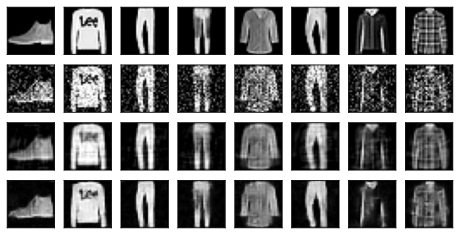

In [17]:
Xf = X.reshape(len(X), -1)
mu = Xf.mean(0)
Sigma = (Xf - mu).T @ (Xf - mu) / len(Xf)      # (784, 784) pixel covariance
A = torch.linalg.solve(Sigma + sigma ** 2 * torch.eye(784, device=X.device),
                       Sigma)                  # (Sigma + sigma^2 I)^-1 Sigma
torch.manual_seed(1)
with torch.no_grad():
    x = X_test[:1000]
    xt = x + sigma * torch.randn_like(x)
    x_lin = (mu + (xt.reshape(1000, -1) - mu) @ A).reshape(x.shape)
    x_net = {seed: xt - sigma * net(xt)        # Tweedie: xt + sigma^2 * score
             for seed, net in nets.items()}
outputs = {'noisy': xt, 'Wiener': x_lin,
           **{f'network, seed {seed}': xh for seed, xh in x_net.items()}}
for name, xh in outputs.items():               # error of each of 1,000 images
    err = ((xh - x) ** 2).flatten(1).mean(1)
    print(f'{name:>16}: per-pixel squared error {err.mean():.4f} '
          f'(standard error {err.std() / math.sqrt(len(err)):.4f})')
d2l.show_gray(torch.cat([x[:8], xt[:8], x_lin[:8], x_net[0][:8]]), 4, 8);

<!-- d2l:prose id=denoising-md-17 fw=all -->

The noisy input has a per-pixel squared error of $\sigma^2 = 0.25$, the optimal linear (Wiener) filter achieves $\approx 0.045$, and both four-layer convolutional networks reach $\approx 0.031$ ($30\%$ lower error, separated by more than 20 standard errors). While the Wiener filter shrinks every image toward a single global linear subspace, leaving blurred edges and background grain, the convolutional network projects noisy points toward the nonlinear manifold of garment images (compare Exercise 3). Because the posterior mean averages over all clean images consistent with $\tilde{\mathbf{x}}$, however, fine high-frequency texture destroyed by the noise is still replaced by a smooth average. Turning a denoiser into a sharpness-preserving generator requires integrating across noise levels (that section and that section).

## Summary

Minimizing the squared denoising error $\mathbb{E}\|D(\tilde{\mathbf{x}}) - \mathbf{x}_0\|^2$ for $\tilde{\mathbf{x}} = \mathbf{x}_0 + \sigma\boldsymbol\epsilon$ recovers the posterior mean $\mathbb{E}[\mathbf{x}_0 \mid \tilde{\mathbf{x}}]$. By Vincent's theorem and Tweedie's formula, $\mathbb{E}[\mathbf{x}_0 \mid \tilde{\mathbf{x}}] = \tilde{\mathbf{x}} + \sigma^2 \nabla_{\tilde{\mathbf{x}}} \log p_\sigma(\tilde{\mathbf{x}})$, so predicting the clean point $\hat{\mathbf{x}}_0$, the noise $\hat{\boldsymbol\epsilon}$, and the score $\hat{\mathbf{s}} = -\hat{\boldsymbol\epsilon}/\sigma$ are affine reparameterizations of a single conditional expectation. Learning the score avoids both the intractable normalizing constant $Z_{\boldsymbol\theta}$ of energy-based models and the Jacobian trace $\nabla \cdot \mathbf{s}$ of explicit score matching. A single noise level $\sigma$, however, faces a sharp trade-off: small $\sigma$ produces high-variance targets, steep gradients near low-dimensional data manifolds, blindness of the Fisher divergence to mode weights, and non-mixing Langevin chains, whereas large $\sigma$ mixes rapidly and recovers mode weights but samples only the heavily smoothed density $p_\sigma$.

## Exercises

1. **Learning without normalization.** Consider the one-dimensional model
   $\tilde{p}(x) = \exp(-E(x))$ with $E(x) = (x - \mu)^2 / (2 \tau^2)$,
   fit to data $x_1, \ldots, x_n$ that take at least two distinct values.
    1. Maximize $\sum_i \log \tilde{p}(x_i)$ over $\mu$ and $\tau$ without
       normalizing. What does $\tilde{p}$ look like away from the data as the
       objective approaches its supremum?
    1. Repeat with the normalized model $\tilde{p} / Z$. Which term of the
       objective prevents the failure of the first part, and what is the
       maximizer?
    1. A network energy usually ends in a linear layer with an output bias
       $c$. Show that the normalized density the equation does
       not depend on $c$. What does gradient ascent on
       $-\sum_i E_{\boldsymbol{\theta}}(\mathbf{x}_i)$ alone do to $c$?
1. [code] **Estimating the normalizer.** A direct way to compute the
   normalizer $Z = \int e^{-E(\mathbf{x})}\, d\mathbf{x}$ of an energy
   is importance sampling (that section): draw
   $\mathbf{x}_1, \ldots, \mathbf{x}_n$ from a proposal $q$ and average the
   weights $w_i = e^{-E(\mathbf{x}_i)} / q(\mathbf{x}_i)$, whose mean is
   $Z$. Take $E(\mathbf{x}) = \|\mathbf{x} - \mathbf{m}\|^2 / 2$, so that
   the target is $\mathcal{N}(\mathbf{m}, \mathbf{I})$ up to normalization,
   and the proposal $q = \mathcal{N}(\mathbf{0}, \mathbf{I})$.
    1. Derive
       $w / Z = \exp(\mathbf{m}^\top \mathbf{x} - \|\mathbf{m}\|^2 / 2)$ and
       show with the moment generating function of a Gaussian that
       $\mathbb{E}_q[w / Z] = 1$ and
       $\mathbb{E}_q[(w / Z)^2] = \exp(\|\mathbf{m}\|^2)$. Conclude that the
       relative standard error of the $n$-sample estimate is
       $\sqrt{(e^{\|\mathbf{m}\|^2} - 1) / n}$. How many samples give a
       relative error of $0.1$ when $\|\mathbf{m}\|^2 = 20$?
    1. Let $\mathbf{m}$ be the all-ones vector in $d$ dimensions, so that
       the proposal is only one standard deviation off in each coordinate.
       With $n = 10^5$, estimate $Z$ for $d \in \{2, 4, 8, 16, 32\}$, report
       the ratio of the estimate to the true $Z = (2\pi)^{d/2}$ and the
       *effective sample size* $(\sum_i w_i)^2 / \sum_i w_i^2$, and compare
       both with the predictions of the first part (the effective sample size
       should be close to $n\, e^{-\|\mathbf{m}\|^2}$). Why does it exceed its prediction once
       $d$ is large, and what does this imply for it as a diagnostic?
    1. An image has hundreds of thousands of coordinates. What do your
       results say about estimating the normalizer of an energy-based model
       of images, and about training one by maximum likelihood?
1. **Data on a line.** Let the data lie on the first coordinate axis of
   $\mathbb{R}^2$, $\mathbf{x}_0 = (u, 0)$ with $u \sim q$ for a smooth positive
   density $q$ on $\mathbb{R}$, so that $p$ has no density on $\mathbb{R}^2$.
    1. Show that
       $p_\sigma(\tilde{\mathbf{x}}) = q_\sigma(\tilde{x}_1)\, \mathcal{N}(\tilde{x}_2;\, 0, \sigma^2)$,
       where $q_\sigma$ is $q$ blurred by $\mathcal{N}(0, \sigma^2)$, and
       write the score $\nabla \log p_\sigma$.
    1. Show that the second component of the score has mean square
       $1 / \sigma^2$ under $p_\sigma$ and slope $-1 / \sigma^2$ in
       $\tilde{x}_2$. What happens to both as $\sigma \to 0$, and what does
       this mean for a network that must represent the score at a small noise
       level?
    1. Apply Tweedie's formula the equation. What does the
       optimal denoiser do to each coordinate of $\tilde{\mathbf{x}}$, and
       which geometric operation does it perform?
    1. Let the data lie on a $k$-dimensional linear subspace of
       $\mathbb{R}^d$ instead. Compute the mean square of the component of the
       score orthogonal to the subspace.
1. **Two-point data and the loss floor.** Let
   $p = \tfrac12 \delta_{-1} + \tfrac12 \delta_{+1}$ in one dimension,
   noised at level $\sigma$.
    1. Compute the posterior mean $\mathbb{E}[x_0 \mid \tilde{x}]$ by Bayes'
       rule, and show that it equals
       $\tilde{x} + \sigma^2 \frac{d}{d\tilde{x}} \log p_\sigma(\tilde{x})$,
       as Tweedie's formula the equation requires.
    1. What does the optimal denoiser return for $\tilde{x} = 0$? Why is
       this the best answer under squared error even though it is not a
       possible clean value?
    1. Write the minimum of the equation as
       $\frac{1}{2 \sigma^4}\, \mathbb{E}\big[\operatorname{tr} \textrm{Cov}(\mathbf{x}_0 \mid \tilde{\mathbf{x}})\big]$,
       and show that it is positive for every data distribution that is not
       concentrated on a single point.
    1. For the two-point data, write the minimum as a one-dimensional
       integral over $\tilde{x}$ and evaluate it by quadrature for
       $\sigma \in \{0.25, 0.5, 1, 2\}$. Multiply each value by $2\sigma^2$ to
       express it in the units of the noise-prediction loss. Explain why this
       rescaled floor vanishes as $\sigma \to 0$, and why it also vanishes as
       $\sigma \to \infty$.
1. [code] **The best linear denoiser.**
    1. Show that the Wiener filter the equation minimizes
       $\mathbb{E}\|D(\tilde{\mathbf{x}}) - \mathbf{x}_0\|^2$ among all affine
       maps $D$ for every data distribution with mean $\boldsymbol{\mu}$ and
       covariance $\boldsymbol{\Sigma}$, and that its squared error per pixel
       is $\frac{1}{d} \sum_i \sigma^2 \lambda_i / (\lambda_i + \sigma^2)$,
       where $\lambda_1, \ldots, \lambda_d$ are the eigenvalues of
       $\boldsymbol{\Sigma}$.
    1. Compute this prediction at $\sigma = 0.5$ from `Sigma` and compare it
       with the printed error of `x_lin`.
    1. Count the eigenvalues of `Sigma` above $\sigma^2$ for
       $\sigma \in \{0.25, 0.5, 1\}$, and plot a few of the corresponding
       eigenvectors as images. What does the filter keep at each noise level?
1. [code] **Escaping a mode.** ● Model the valley between the two lower modes
   of the running example in one dimension by the equal mixture of
   $\mathcal{N}(-2.5, 0.25)$ and $\mathcal{N}(2.5, 0.25)$, with potential
   $U = -\log p$, wells at $a = \pm 2.5$, and the barrier at $b = 0$. When
   the barrier height $\Delta U = U(b) - U(a)$ is large compared with one,
   Kramers' formula [@Kramers.1940] gives the expected time for the
   diffusion $dX = -\tfrac12 U'(X)\, dt + dW$, the continuous-time limit of
   the equation, to pass from one well to the other:

   $$
   \tau \approx \frac{4 \pi}{\sqrt{U''(a)\, |U''(b)|}}\, e^{\Delta U}.
   $$

    1. Compute $\Delta U$, $U''(a)$ and $U''(b)$, and convert $\tau$ into a
       number of Langevin steps at $h = 0.05$.
    1. Mode 3 of the running example lies about $4.7$ from mode 1 (and from
       mode 2), closer than the $5$ between the two lower modes. Evaluate $U = -\log p$ of the running example along the
       segment between the two means, read off the barrier height, and
       estimate the crossing time in the same way. How many of 2,000 chains
       should cross from mode 1 to mode 3 in 2,000 steps?
    1. Repeat the first part for $p_\sigma$ at $\sigma = 0.3$ and
       $\sigma = 1$, treating the result as an order of magnitude where
       $\Delta U$ is small, and use it to explain the weights of the
       $\sigma = 1$ chains. How many of 2,000 chains should cross in 2,000
       steps at $\sigma = 0.3$, and does the printed row of `p_0.3` agree?
       The networks trained at $\sigma = 0.3$ move at least twice as much
       mass. What does that say about the learned field between the modes?

[Discussions](https://d2l.discourse.group/t/36818)